In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)

PyTorch version: 2.9.0
Torchvision version: 0.24.0


In [2]:
# CIFAR-10 transform
transform = transforms.Compose([
    transforms.ToTensor()
])

# Download training dataset
trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Create DataLoader
trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=8,
    shuffle=True
)

# CIFAR-10 class names
classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

print("Training samples:", len(trainset))

100%|████████████████████████████████████████| 170M/170M [45:00<00:00, 63.1kB/s]


Training samples: 50000


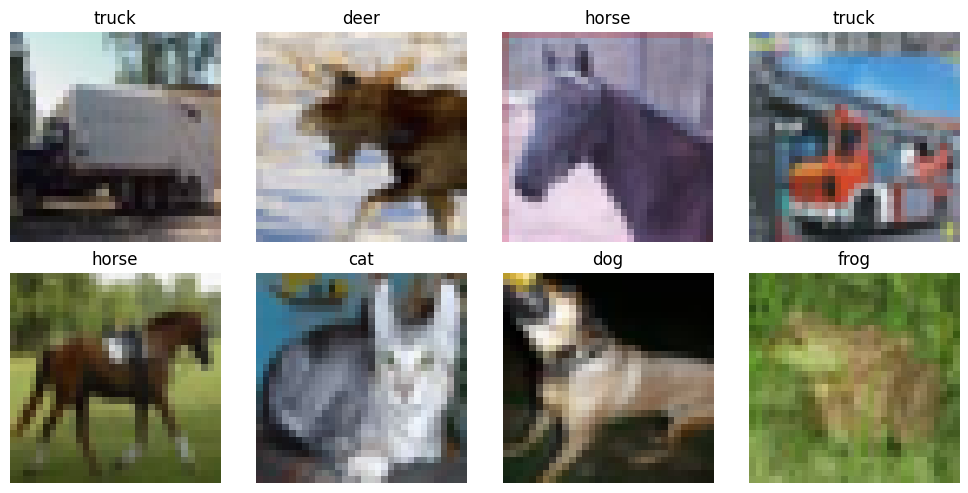

In [3]:
# Get one batch
images, labels = next(iter(trainloader))

# Show 8 images
fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0)
    ax.imshow(image)
    ax.set_title(classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
import torch.nn as nn
import torch.optim as optim

class SimpleMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(32 * 32 * 3, 512)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu1(x)

        x = self.fc2(x)
        x = self.relu2(x)

        x = self.fc3(x)

        return x

In [5]:
model = SimpleMLP()

print(model)

SimpleMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=10, bias=True)
)


In [6]:
images, labels = next(iter(trainloader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([8, 3, 32, 32])
Output shape: torch.Size([8, 10])


In [7]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.SGD(model.parameters(), lr=0.01)

# One training step
optimizer.zero_grad()

outputs = model(images)

loss = criterion(outputs, labels)

loss.backward()

optimizer.step()

print("Loss:", loss.item())

Loss: 2.280491828918457


In [8]:
# Re-create model and optimizer
model = SimpleMLP()

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

num_epochs = 5
loss_history = []

for epoch in range(num_epochs):

    running_loss = 0.0

    for images, labels in trainloader:

        # 1. Clear old gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(images)

        # 3. Compute loss
        loss = criterion(outputs, labels)

        # 4. Backward pass
        loss.backward()

        # 5. Update weights
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(trainloader)
    loss_history.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs}, "
        f"Loss: {average_loss:.4f}"
    )

print("Training finished.")

Epoch 1/5, Loss: 1.8682
Epoch 2/5, Loss: 1.6593
Epoch 3/5, Loss: 1.5686
Epoch 4/5, Loss: 1.5067
Epoch 5/5, Loss: 1.4589
Training finished.


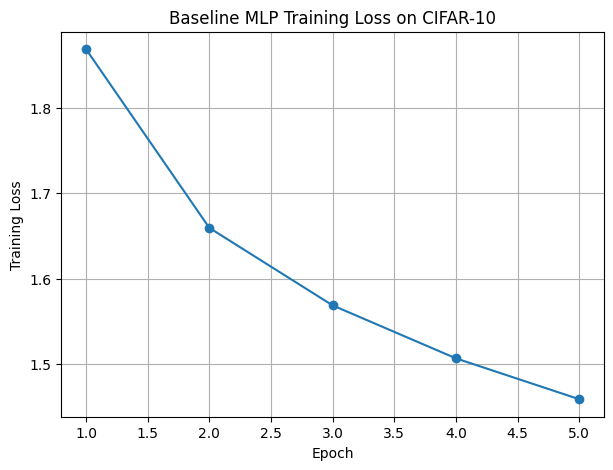

In [9]:
plt.figure(figsize=(7, 5))

plt.plot(
    range(1, num_epochs + 1),
    loss_history,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Baseline MLP Training Loss on CIFAR-10")
plt.grid(True)

plt.show()

In [10]:
# Load CIFAR-10 test set
testset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False
)

print("Test samples:", len(testset))

Test samples: 10000


In [11]:
correct = 0
total = 0

model.eval()

with torch.no_grad():
    for images, labels in testloader:

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Accuracy: 48.01%


In [12]:
def zero_initialize(model):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.constant_(layer.weight, 0.0)
            nn.init.constant_(layer.bias, 0.0)

In [13]:
zero_model = SimpleMLP()

zero_initialize(zero_model)

print(zero_model.fc1.weight[0][:10])

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], grad_fn=<SliceBackward0>)


In [14]:
zero_criterion = nn.CrossEntropyLoss()
zero_optimizer = optim.SGD(zero_model.parameters(), lr=0.01)

zero_num_epochs = 5
zero_loss_history = []

for epoch in range(zero_num_epochs):

    running_loss = 0.0

    zero_model.train()

    for images, labels in trainloader:

        zero_optimizer.zero_grad()

        outputs = zero_model(images)

        loss = zero_criterion(outputs, labels)

        loss.backward()

        zero_optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(trainloader)
    zero_loss_history.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{zero_num_epochs}, "
        f"Loss: {average_loss:.4f}"
    )

print("Zero initialization training finished.")


Epoch 1/5, Loss: 2.3030
Epoch 2/5, Loss: 2.3029
Epoch 3/5, Loss: 2.3029
Epoch 4/5, Loss: 2.3030
Epoch 5/5, Loss: 2.3029
Zero initialization training finished.


In [15]:
def print_gradient_norms(model):
    for name, parameter in model.named_parameters():
        if parameter.grad is not None:
            grad_norm = parameter.grad.norm().item()
            print(f"{name}: {grad_norm:.8f}")

In [16]:
images, labels = next(iter(trainloader))

zero_optimizer.zero_grad()

outputs = zero_model(images)
loss = zero_criterion(outputs, labels)

loss.backward()

print("Gradient norms:")
print_gradient_norms(zero_model)

Gradient norms:
fc1.weight: 0.00000000
fc1.bias: 0.00000000
fc2.weight: 0.00000000
fc2.bias: 0.00000000
fc3.weight: 0.00000000
fc3.bias: 0.16109550


In [17]:
def xavier_initialize(model):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.xavier_normal_(layer.weight)
            nn.init.constant_(layer.bias, 0.0)

In [18]:
xavier_model = SimpleMLP()

xavier_initialize(xavier_model)

print(xavier_model.fc1.weight[0][:10])

tensor([ 0.0059,  0.0296,  0.0060,  0.0277, -0.0214,  0.0185, -0.0035, -0.0035,
        -0.0213,  0.0074], grad_fn=<SliceBackward0>)


In [19]:
xavier_criterion = nn.CrossEntropyLoss()
xavier_optimizer = optim.SGD(
    xavier_model.parameters(),
    lr=0.01
)

images, labels = next(iter(trainloader))

xavier_optimizer.zero_grad()

outputs = xavier_model(images)
loss = xavier_criterion(outputs, labels)

loss.backward()

print("Xavier gradient norms:")
print_gradient_norms(xavier_model)

Xavier gradient norms:
fc1.weight: 8.05469608
fc1.bias: 0.25799826
fc2.weight: 3.75232983
fc2.bias: 0.31680450
fc3.weight: 2.61013484
fc3.bias: 0.36008838


In [20]:
xavier_num_epochs = 5
xavier_loss_history = []

for epoch in range(xavier_num_epochs):

    running_loss = 0.0

    xavier_model.train()

    for images, labels in trainloader:

        xavier_optimizer.zero_grad()

        outputs = xavier_model(images)

        loss = xavier_criterion(outputs, labels)

        loss.backward()

        xavier_optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(trainloader)
    xavier_loss_history.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{xavier_num_epochs}, "
        f"Loss: {average_loss:.4f}"
    )

print("Xavier initialization training finished.")

Epoch 1/5, Loss: 1.8032
Epoch 2/5, Loss: 1.6164
Epoch 3/5, Loss: 1.5306
Epoch 4/5, Loss: 1.4750
Epoch 5/5, Loss: 1.4279
Xavier initialization training finished.


In [21]:
correct = 0
total = 0

xavier_model.eval()

with torch.no_grad():
    for images, labels in testloader:

        outputs = xavier_model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

xavier_test_accuracy = 100 * correct / total

print(f"Xavier Test Accuracy: {xavier_test_accuracy:.2f}%")

Xavier Test Accuracy: 47.32%


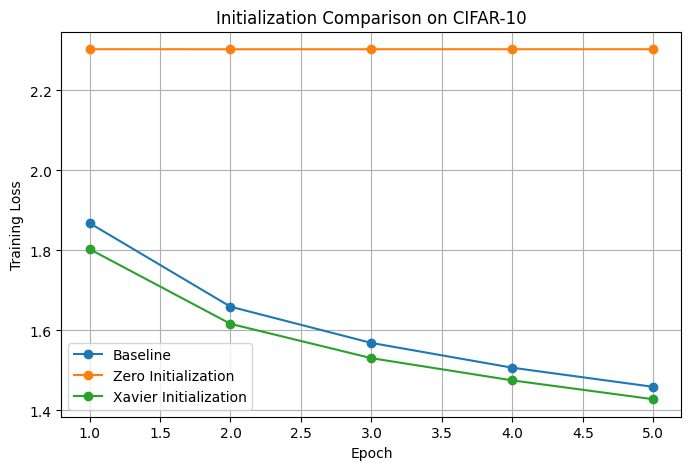

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, num_epochs + 1),
    loss_history,
    marker="o",
    label="Baseline"
)

plt.plot(
    range(1, zero_num_epochs + 1),
    zero_loss_history,
    marker="o",
    label="Zero Initialization"
)

plt.plot(
    range(1, xavier_num_epochs + 1),
    xavier_loss_history,
    marker="o",
    label="Xavier Initialization"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Initialization Comparison on CIFAR-10")
plt.legend()
plt.grid(True)

plt.show()

In [23]:
def he_initialize(model):
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(
                layer.weight,
                nonlinearity="relu"
            )
            nn.init.constant_(layer.bias, 0.0)

In [24]:
he_model = SimpleMLP()

he_initialize(he_model)

print(he_model.fc1.weight[0][:10])

tensor([-1.1740e-02, -1.6071e-02,  1.7379e-02,  2.3213e-02, -4.3819e-02,
        -1.7158e-02, -7.5928e-05, -1.8576e-03,  1.4603e-03,  3.8206e-02],
       grad_fn=<SliceBackward0>)


In [25]:
he_criterion = nn.CrossEntropyLoss()
he_optimizer = optim.SGD(
    he_model.parameters(),
    lr=0.01
)

images, labels = next(iter(trainloader))

he_optimizer.zero_grad()

outputs = he_model(images)
loss = he_criterion(outputs, labels)

loss.backward()

print("He gradient norms:")
print_gradient_norms(he_model)

He gradient norms:
fc1.weight: 10.63903332
fc1.bias: 0.31515828
fc2.weight: 4.54047728
fc2.bias: 0.29906720
fc3.weight: 3.07018447
fc3.bias: 0.26956019


In [26]:
he_num_epochs = 5
he_loss_history = []

for epoch in range(he_num_epochs):

    running_loss = 0.0
    he_model.train()

    for images, labels in trainloader:

        he_optimizer.zero_grad()

        outputs = he_model(images)

        loss = he_criterion(outputs, labels)

        loss.backward()

        he_optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(trainloader)
    he_loss_history.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{he_num_epochs}, "
        f"Loss: {average_loss:.4f}"
    )

print("He initialization training finished.")

Epoch 1/5, Loss: 1.8172
Epoch 2/5, Loss: 1.6305
Epoch 3/5, Loss: 1.5457
Epoch 4/5, Loss: 1.4852
Epoch 5/5, Loss: 1.4383
He initialization training finished.


In [27]:
correct = 0
total = 0

he_model.eval()

with torch.no_grad():
    for images, labels in testloader:

        outputs = he_model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

he_test_accuracy = 100 * correct / total

print(f"He Test Accuracy: {he_test_accuracy:.2f}%")

He Test Accuracy: 48.23%


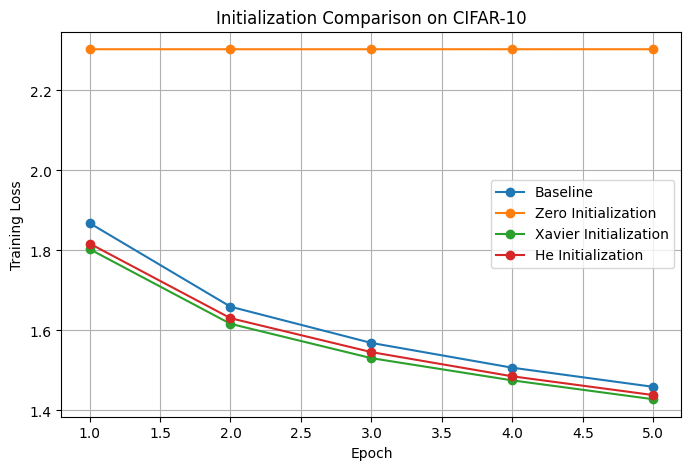

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(range(1, num_epochs + 1), loss_history, marker="o", label="Baseline")
plt.plot(range(1, zero_num_epochs + 1), zero_loss_history, marker="o", label="Zero Initialization")
plt.plot(range(1, xavier_num_epochs + 1), xavier_loss_history, marker="o", label="Xavier Initialization")
plt.plot(range(1, he_num_epochs + 1), he_loss_history, marker="o", label="He Initialization")

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Initialization Comparison on CIFAR-10")
plt.legend()
plt.grid(True)

plt.show()

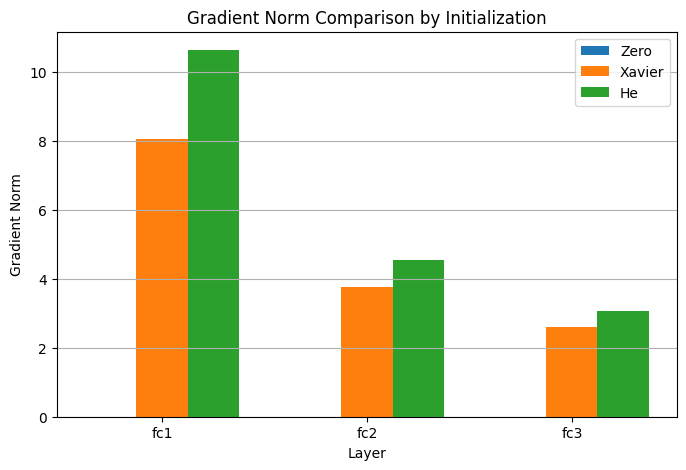

In [29]:
layer_names = ["fc1", "fc2", "fc3"]

zero_gradients = [0.0, 0.0, 0.0]
xavier_gradients = [8.05469608, 3.75232983, 2.61013484]
he_gradients = [10.63903332, 4.54047728, 3.07018447]

x = np.arange(len(layer_names))
width = 0.25

plt.figure(figsize=(8, 5))

plt.bar(x - width, zero_gradients, width, label="Zero")
plt.bar(x, xavier_gradients, width, label="Xavier")
plt.bar(x + width, he_gradients, width, label="He")

plt.xticks(x, layer_names)
plt.xlabel("Layer")
plt.ylabel("Gradient Norm")
plt.title("Gradient Norm Comparison by Initialization")
plt.legend()
plt.grid(axis="y")

plt.show()

In [30]:
def train_model(model, optimizer, trainloader, criterion, num_epochs=5):
    loss_history = []

    for epoch in range(num_epochs):

        model.train()
        running_loss = 0.0

        for images, labels in trainloader:

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        average_loss = running_loss / len(trainloader)
        loss_history.append(average_loss)

        print(
            f"Epoch {epoch + 1}/{num_epochs}, "
            f"Loss: {average_loss:.4f}"
        )

    return loss_history

In [31]:
def evaluate_model(model, testloader):
    correct = 0
    total = 0

    model.eval()

    with torch.no_grad():
        for images, labels in testloader:

            outputs = model(images)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total

    return accuracy

In [32]:
# SGD model
sgd_model = SimpleMLP()
he_initialize(sgd_model)

sgd_optimizer = optim.SGD(
    sgd_model.parameters(),
    lr=0.01
)

criterion = nn.CrossEntropyLoss()

print("Training with SGD...")
sgd_loss_history = train_model(
    sgd_model,
    sgd_optimizer,
    trainloader,
    criterion,
    num_epochs=5
)

sgd_accuracy = evaluate_model(
    sgd_model,
    testloader
)

print(f"SGD Test Accuracy: {sgd_accuracy:.2f}%")

Training with SGD...
Epoch 1/5, Loss: 1.8123
Epoch 2/5, Loss: 1.6228
Epoch 3/5, Loss: 1.5372
Epoch 4/5, Loss: 1.4774
Epoch 5/5, Loss: 1.4305
SGD Test Accuracy: 48.78%


In [35]:
# Momentum model
momentum_model_v2 = SimpleMLP()
he_initialize(momentum_model_v2)

momentum_optimizer_v2 = optim.SGD(
    momentum_model_v2.parameters(),
    lr=0.001,
    momentum=0.9
)

print("Training Momentum with lr=0.001...")

momentum_loss_history_v2 = train_model(
    momentum_model_v2,
    momentum_optimizer_v2,
    trainloader,
    criterion,
    num_epochs=5
)

momentum_accuracy_v2 = evaluate_model(
    momentum_model_v2,
    testloader
)

print(f"Momentum Test Accuracy: {momentum_accuracy_v2:.2f}%")

Training Momentum with lr=0.001...
Epoch 1/5, Loss: 1.8076
Epoch 2/5, Loss: 1.6245
Epoch 3/5, Loss: 1.5376
Epoch 4/5, Loss: 1.4837
Epoch 5/5, Loss: 1.4374
Momentum Test Accuracy: 48.13%


In [36]:
# Adam model
adam_model_v2 = SimpleMLP()
he_initialize(adam_model_v2)

adam_optimizer_v2 = optim.Adam(
    adam_model_v2.parameters(),
    lr=0.0003
)

print("Training Adam with lr=0.0003...")

adam_loss_history_v2 = train_model(
    adam_model_v2,
    adam_optimizer_v2,
    trainloader,
    criterion,
    num_epochs=5
)

adam_accuracy_v2 = evaluate_model(
    adam_model_v2,
    testloader
)

print(f"Adam Test Accuracy: {adam_accuracy_v2:.2f}%")

Training Adam with lr=0.0003...
Epoch 1/5, Loss: 1.8329
Epoch 2/5, Loss: 1.6417
Epoch 3/5, Loss: 1.5554
Epoch 4/5, Loss: 1.4998
Epoch 5/5, Loss: 1.4558
Adam Test Accuracy: 47.32%


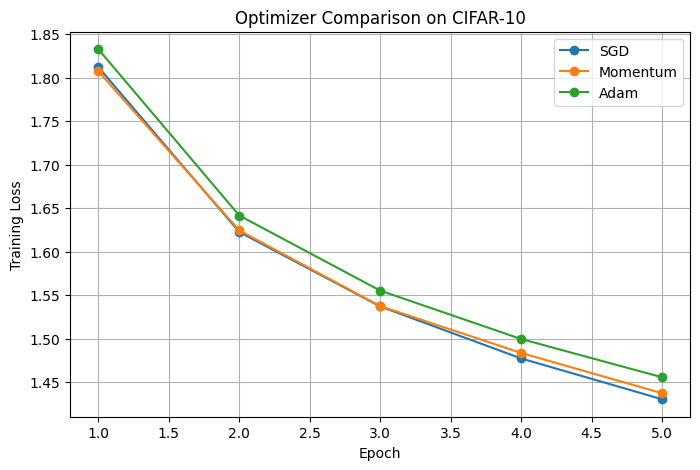

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 6),
    sgd_loss_history,
    marker="o",
    label="SGD"
)

plt.plot(
    range(1, 6),
    momentum_loss_history_v2,
    marker="o",
    label="Momentum"
)

plt.plot(
    range(1, 6),
    adam_loss_history_v2,
    marker="o",
    label="Adam"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Optimizer Comparison on CIFAR-10")
plt.legend()
plt.grid(True)

plt.show()

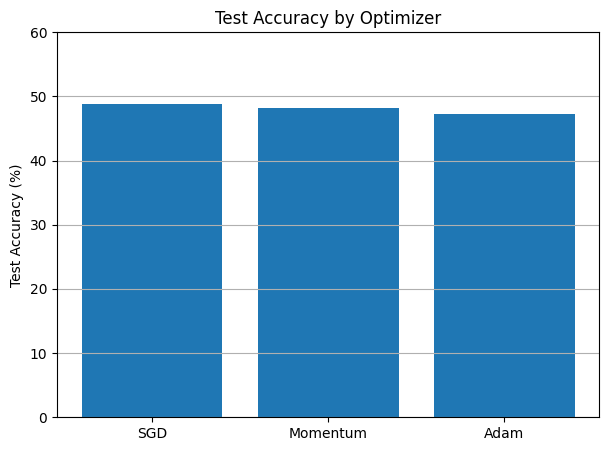

In [38]:
optimizer_names = ["SGD", "Momentum", "Adam"]

accuracies = [
    sgd_accuracy,
    momentum_accuracy_v2,
    adam_accuracy_v2
]

plt.figure(figsize=(7, 5))

plt.bar(optimizer_names, accuracies)

plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy by Optimizer")
plt.ylim(0, 60)
plt.grid(axis="y")

plt.show()

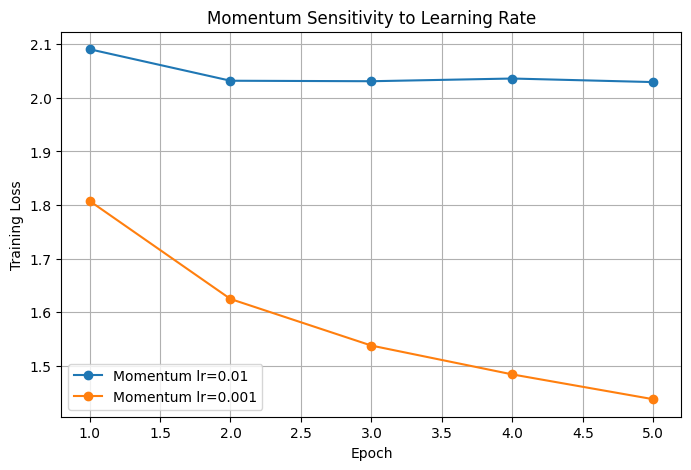

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 6),
    momentum_loss_history,
    marker="o",
    label="Momentum lr=0.01"
)

plt.plot(
    range(1, 6),
    momentum_loss_history_v2,
    marker="o",
    label="Momentum lr=0.001"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Momentum Sensitivity to Learning Rate")
plt.legend()
plt.grid(True)

plt.show()

In [40]:
from torch.utils.data import Subset, DataLoader

small_trainset = Subset(
    trainset,
    range(5000)
)

small_trainloader = DataLoader(
    small_trainset,
    batch_size=64,
    shuffle=True
)

print("Small training samples:", len(small_trainset))

Small training samples: 5000


In [41]:
class LargeMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(32 * 32 * 3, 1024)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(1024, 512)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(512, 256)
        self.relu3 = nn.ReLU()

        self.fc4 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)

        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.relu3(self.fc3(x))

        x = self.fc4(x)

        return x

In [42]:
overfit_model = LargeMLP()
he_initialize(overfit_model)

print(overfit_model)

LargeMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=1024, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=1024, out_features=512, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=512, out_features=256, bias=True)
  (relu3): ReLU()
  (fc4): Linear(in_features=256, out_features=10, bias=True)
)


In [43]:
def train_with_validation(
    model,
    optimizer,
    trainloader,
    testloader,
    criterion,
    num_epochs=20
):
    train_loss_history = []
    test_loss_history = []
    train_acc_history = []
    test_acc_history = []

    for epoch in range(num_epochs):

        # ----- Training -----
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in trainloader:

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(trainloader)
        train_accuracy = 100 * correct / total

        # ----- Evaluation -----
        model.eval()

        test_running_loss = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for images, labels in testloader:

                outputs = model(images)
                loss = criterion(outputs, labels)

                test_running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()

        test_loss = test_running_loss / len(testloader)
        test_accuracy = 100 * test_correct / test_total

        # Save results
        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        train_acc_history.append(train_accuracy)
        test_acc_history.append(test_accuracy)

        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Test Acc: {test_accuracy:.2f}%"
        )

    return (
        train_loss_history,
        test_loss_history,
        train_acc_history,
        test_acc_history
    )

In [44]:
overfit_criterion = nn.CrossEntropyLoss()

overfit_optimizer = optim.Adam(
    overfit_model.parameters(),
    lr=0.001
)

(
    overfit_train_loss,
    overfit_test_loss,
    overfit_train_acc,
    overfit_test_acc
) = train_with_validation(
    overfit_model,
    overfit_optimizer,
    small_trainloader,
    testloader,
    overfit_criterion,
    num_epochs=20
)

Epoch 1/20 | Train Loss: 2.3785 | Test Loss: 2.1529 | Train Acc: 19.96% | Test Acc: 21.64%
Epoch 2/20 | Train Loss: 1.9681 | Test Loss: 1.9770 | Train Acc: 27.44% | Test Acc: 27.73%
Epoch 3/20 | Train Loss: 1.8562 | Test Loss: 1.9386 | Train Acc: 33.42% | Test Acc: 29.89%
Epoch 4/20 | Train Loss: 1.8025 | Test Loss: 1.9185 | Train Acc: 35.10% | Test Acc: 31.64%
Epoch 5/20 | Train Loss: 1.7699 | Test Loss: 1.9918 | Train Acc: 36.28% | Test Acc: 30.57%
Epoch 6/20 | Train Loss: 1.7143 | Test Loss: 1.7839 | Train Acc: 37.46% | Test Acc: 35.85%
Epoch 7/20 | Train Loss: 1.6717 | Test Loss: 1.7463 | Train Acc: 39.28% | Test Acc: 36.85%
Epoch 8/20 | Train Loss: 1.6566 | Test Loss: 1.7786 | Train Acc: 39.86% | Test Acc: 35.81%
Epoch 9/20 | Train Loss: 1.6405 | Test Loss: 1.7490 | Train Acc: 40.08% | Test Acc: 36.87%
Epoch 10/20 | Train Loss: 1.5888 | Test Loss: 1.7499 | Train Acc: 42.50% | Test Acc: 38.96%
Epoch 11/20 | Train Loss: 1.5420 | Test Loss: 1.6993 | Train Acc: 43.76% | Test Acc: 39.8

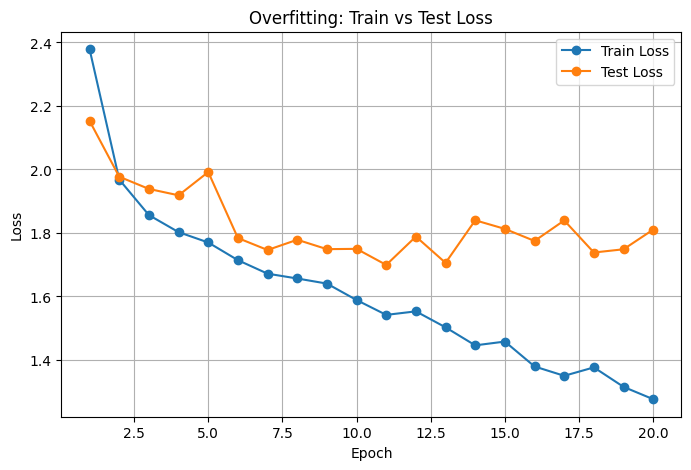

In [45]:
epochs = range(1, 21)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    overfit_train_loss,
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    overfit_test_loss,
    marker="o",
    label="Test Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Overfitting: Train vs Test Loss")
plt.legend()
plt.grid(True)

plt.show()

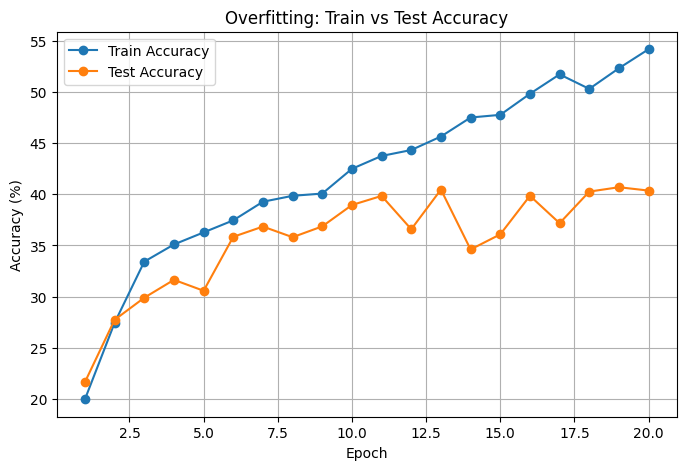

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    overfit_train_acc,
    marker="o",
    label="Train Accuracy"
)

plt.plot(
    epochs,
    overfit_test_acc,
    marker="o",
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Overfitting: Train vs Test Accuracy")
plt.legend()
plt.grid(True)

plt.show()

In [47]:
class DropoutMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(32 * 32 * 3, 1024)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.5)

        self.fc2 = nn.Linear(1024, 512)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.5)

        self.fc3 = nn.Linear(512, 256)
        self.relu3 = nn.ReLU()
        self.dropout3 = nn.Dropout(0.5)

        self.fc4 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)

        x = self.relu1(self.fc1(x))
        x = self.dropout1(x)

        x = self.relu2(self.fc2(x))
        x = self.dropout2(x)

        x = self.relu3(self.fc3(x))
        x = self.dropout3(x)

        x = self.fc4(x)

        return x

In [48]:
dropout_model = DropoutMLP()
he_initialize(dropout_model)

dropout_optimizer = optim.Adam(
    dropout_model.parameters(),
    lr=0.001
)

dropout_criterion = nn.CrossEntropyLoss()

(
    dropout_train_loss,
    dropout_test_loss,
    dropout_train_acc,
    dropout_test_acc
) = train_with_validation(
    dropout_model,
    dropout_optimizer,
    small_trainloader,
    testloader,
    dropout_criterion,
    num_epochs=20
)

Epoch 1/20 | Train Loss: 2.8097 | Test Loss: 2.2639 | Train Acc: 11.90% | Test Acc: 16.73%
Epoch 2/20 | Train Loss: 2.2410 | Test Loss: 2.2293 | Train Acc: 15.20% | Test Acc: 18.38%
Epoch 3/20 | Train Loss: 2.2082 | Test Loss: 2.1671 | Train Acc: 16.28% | Test Acc: 20.43%
Epoch 4/20 | Train Loss: 2.1686 | Test Loss: 2.1311 | Train Acc: 17.16% | Test Acc: 20.21%
Epoch 5/20 | Train Loss: 2.1609 | Test Loss: 2.0757 | Train Acc: 17.46% | Test Acc: 23.52%
Epoch 6/20 | Train Loss: 2.1477 | Test Loss: 2.0831 | Train Acc: 18.24% | Test Acc: 21.78%
Epoch 7/20 | Train Loss: 2.1520 | Test Loss: 2.0861 | Train Acc: 17.34% | Test Acc: 20.91%
Epoch 8/20 | Train Loss: 2.1098 | Test Loss: 2.0531 | Train Acc: 19.08% | Test Acc: 23.06%
Epoch 9/20 | Train Loss: 2.1150 | Test Loss: 2.0569 | Train Acc: 18.90% | Test Acc: 22.69%
Epoch 10/20 | Train Loss: 2.1302 | Test Loss: 2.1217 | Train Acc: 18.54% | Test Acc: 20.85%
Epoch 11/20 | Train Loss: 2.1327 | Test Loss: 2.0720 | Train Acc: 17.70% | Test Acc: 20.6

In [49]:
class DropoutMLP02(nn.Module):
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(32 * 32 * 3, 1024)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(0.2)

        self.fc2 = nn.Linear(1024, 512)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(0.2)

        self.fc3 = nn.Linear(512, 256)
        self.relu3 = nn.ReLU()
        self.dropout3 = nn.Dropout(0.2)

        self.fc4 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)

        x = self.relu1(self.fc1(x))
        x = self.dropout1(x)

        x = self.relu2(self.fc2(x))
        x = self.dropout2(x)

        x = self.relu3(self.fc3(x))
        x = self.dropout3(x)

        x = self.fc4(x)

        return x

In [50]:
dropout02_model = DropoutMLP02()
he_initialize(dropout02_model)

dropout02_optimizer = optim.Adam(
    dropout02_model.parameters(),
    lr=0.001
)

(
    dropout02_train_loss,
    dropout02_test_loss,
    dropout02_train_acc,
    dropout02_test_acc
) = train_with_validation(
    dropout02_model,
    dropout02_optimizer,
    small_trainloader,
    testloader,
    nn.CrossEntropyLoss(),
    num_epochs=20
)

Epoch 1/20 | Train Loss: 2.5549 | Test Loss: 2.1349 | Train Acc: 13.68% | Test Acc: 19.05%
Epoch 2/20 | Train Loss: 2.1245 | Test Loss: 2.0333 | Train Acc: 20.30% | Test Acc: 23.08%
Epoch 3/20 | Train Loss: 2.0275 | Test Loss: 1.9867 | Train Acc: 23.70% | Test Acc: 26.95%
Epoch 4/20 | Train Loss: 1.9785 | Test Loss: 1.9584 | Train Acc: 27.76% | Test Acc: 27.50%
Epoch 5/20 | Train Loss: 1.9329 | Test Loss: 1.8473 | Train Acc: 28.56% | Test Acc: 32.41%
Epoch 6/20 | Train Loss: 1.9049 | Test Loss: 1.8821 | Train Acc: 30.36% | Test Acc: 31.31%
Epoch 7/20 | Train Loss: 1.8745 | Test Loss: 1.8742 | Train Acc: 31.42% | Test Acc: 32.00%
Epoch 8/20 | Train Loss: 1.8633 | Test Loss: 1.8520 | Train Acc: 32.70% | Test Acc: 33.61%
Epoch 9/20 | Train Loss: 1.8391 | Test Loss: 1.8135 | Train Acc: 33.14% | Test Acc: 33.38%
Epoch 10/20 | Train Loss: 1.8266 | Test Loss: 1.7780 | Train Acc: 32.94% | Test Acc: 35.75%
Epoch 11/20 | Train Loss: 1.8105 | Test Loss: 1.8038 | Train Acc: 33.26% | Test Acc: 35.6

In [51]:
weight_decay_model = LargeMLP()
he_initialize(weight_decay_model)

weight_decay_optimizer = optim.Adam(
    weight_decay_model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

(
    wd_train_loss,
    wd_test_loss,
    wd_train_acc,
    wd_test_acc
) = train_with_validation(
    weight_decay_model,
    weight_decay_optimizer,
    small_trainloader,
    testloader,
    nn.CrossEntropyLoss(),
    num_epochs=20
)

Epoch 1/20 | Train Loss: 2.5553 | Test Loss: 2.1212 | Train Acc: 17.56% | Test Acc: 22.47%
Epoch 2/20 | Train Loss: 1.9869 | Test Loss: 1.9997 | Train Acc: 27.78% | Test Acc: 27.63%
Epoch 3/20 | Train Loss: 1.8846 | Test Loss: 1.9277 | Train Acc: 31.74% | Test Acc: 29.17%
Epoch 4/20 | Train Loss: 1.8214 | Test Loss: 1.8802 | Train Acc: 33.90% | Test Acc: 31.61%
Epoch 5/20 | Train Loss: 1.7833 | Test Loss: 1.8963 | Train Acc: 36.28% | Test Acc: 32.03%
Epoch 6/20 | Train Loss: 1.7482 | Test Loss: 1.8088 | Train Acc: 37.08% | Test Acc: 34.37%
Epoch 7/20 | Train Loss: 1.6983 | Test Loss: 1.7753 | Train Acc: 38.42% | Test Acc: 35.26%
Epoch 8/20 | Train Loss: 1.6546 | Test Loss: 1.8310 | Train Acc: 40.34% | Test Acc: 34.16%
Epoch 9/20 | Train Loss: 1.6568 | Test Loss: 1.7295 | Train Acc: 40.04% | Test Acc: 38.79%
Epoch 10/20 | Train Loss: 1.5939 | Test Loss: 1.7383 | Train Acc: 42.48% | Test Acc: 38.40%
Epoch 11/20 | Train Loss: 1.5598 | Test Loss: 1.8068 | Train Acc: 43.86% | Test Acc: 37.2

In [52]:
augment_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

In [53]:
augmented_trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=augment_transform
)

In [54]:
augmented_small_trainset = Subset(
    augmented_trainset,
    range(5000)
)

augmented_trainloader = DataLoader(
    augmented_small_trainset,
    batch_size=64,
    shuffle=True
)

print("Augmented training samples:", len(augmented_small_trainset))

Augmented training samples: 5000


In [55]:
augmentation_model = LargeMLP()
he_initialize(augmentation_model)

augmentation_optimizer = optim.Adam(
    augmentation_model.parameters(),
    lr=0.001
)

augmentation_criterion = nn.CrossEntropyLoss()

(
    aug_train_loss,
    aug_test_loss,
    aug_train_acc,
    aug_test_acc
) = train_with_validation(
    augmentation_model,
    augmentation_optimizer,
    augmented_trainloader,
    testloader,
    augmentation_criterion,
    num_epochs=20
)

Epoch 1/20 | Train Loss: 2.4154 | Test Loss: 2.0772 | Train Acc: 17.08% | Test Acc: 21.08%
Epoch 2/20 | Train Loss: 2.0514 | Test Loss: 2.2802 | Train Acc: 24.84% | Test Acc: 18.20%
Epoch 3/20 | Train Loss: 2.0088 | Test Loss: 2.0096 | Train Acc: 25.88% | Test Acc: 24.37%
Epoch 4/20 | Train Loss: 1.9916 | Test Loss: 1.9042 | Train Acc: 26.36% | Test Acc: 30.60%
Epoch 5/20 | Train Loss: 1.9464 | Test Loss: 1.9084 | Train Acc: 28.08% | Test Acc: 28.90%
Epoch 6/20 | Train Loss: 1.9245 | Test Loss: 1.9044 | Train Acc: 29.16% | Test Acc: 30.25%
Epoch 7/20 | Train Loss: 1.8976 | Test Loss: 1.8528 | Train Acc: 30.86% | Test Acc: 32.64%
Epoch 8/20 | Train Loss: 1.8858 | Test Loss: 1.8301 | Train Acc: 30.16% | Test Acc: 33.47%
Epoch 9/20 | Train Loss: 1.8738 | Test Loss: 1.8342 | Train Acc: 31.66% | Test Acc: 33.77%
Epoch 10/20 | Train Loss: 1.8554 | Test Loss: 1.8482 | Train Acc: 32.02% | Test Acc: 33.15%
Epoch 11/20 | Train Loss: 1.8388 | Test Loss: 1.8441 | Train Acc: 32.74% | Test Acc: 33.4

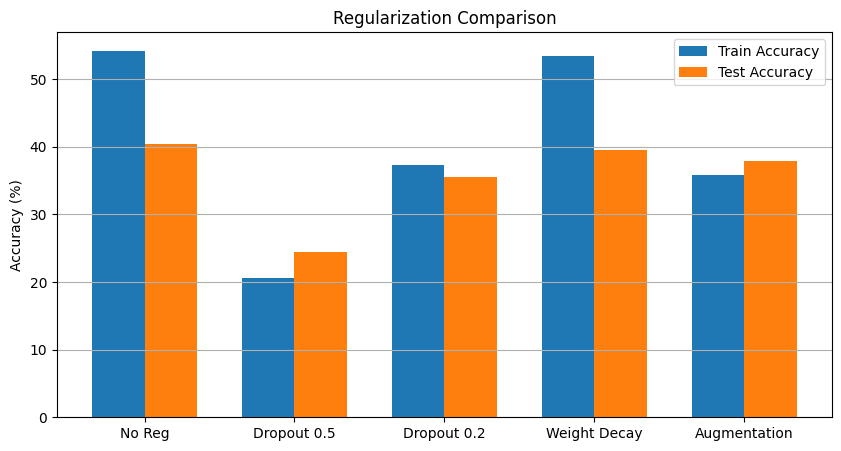

In [56]:
methods = [
    "No Reg",
    "Dropout 0.5",
    "Dropout 0.2",
    "Weight Decay",
    "Augmentation"
]

train_accs = [
    overfit_train_acc[-1],
    dropout_train_acc[-1],
    dropout02_train_acc[-1],
    wd_train_acc[-1],
    aug_train_acc[-1]
]

test_accs = [
    overfit_test_acc[-1],
    dropout_test_acc[-1],
    dropout02_test_acc[-1],
    wd_test_acc[-1],
    aug_test_acc[-1]
]

x = np.arange(len(methods))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, train_accs, width, label="Train Accuracy")
plt.bar(x + width/2, test_accs, width, label="Test Accuracy")

plt.xticks(x, methods)
plt.ylabel("Accuracy (%)")
plt.title("Regularization Comparison")
plt.legend()
plt.grid(axis="y")

plt.show()

In [57]:
import copy

def train_with_early_stopping(
    model,
    optimizer,
    trainloader,
    testloader,
    criterion,
    num_epochs=50,
    patience=5
):
    train_loss_history = []
    test_loss_history = []
    train_acc_history = []
    test_acc_history = []

    best_test_loss = float("inf")
    best_model_state = None
    patience_counter = 0

    for epoch in range(num_epochs):

        # Training
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in trainloader:

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(trainloader)
        train_accuracy = 100 * correct / total

        # Evaluation
        model.eval()

        test_running_loss = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for images, labels in testloader:

                outputs = model(images)
                loss = criterion(outputs, labels)

                test_running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()

        test_loss = test_running_loss / len(testloader)
        test_accuracy = 100 * test_correct / test_total

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        train_acc_history.append(train_accuracy)
        test_acc_history.append(test_accuracy)

        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Test Acc: {test_accuracy:.2f}%"
        )

        # Early stopping check
        if test_loss < best_test_loss:
            best_test_loss = test_loss
            best_model_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch + 1}")
            break

    model.load_state_dict(best_model_state)

    return (
        train_loss_history,
        test_loss_history,
        train_acc_history,
        test_acc_history
    )

In [58]:
early_stop_model = LargeMLP()
he_initialize(early_stop_model)

early_stop_optimizer = optim.Adam(
    early_stop_model.parameters(),
    lr=0.001
)

(
    es_train_loss,
    es_test_loss,
    es_train_acc,
    es_test_acc
) = train_with_early_stopping(
    early_stop_model,
    early_stop_optimizer,
    small_trainloader,
    testloader,
    nn.CrossEntropyLoss(),
    num_epochs=50,
    patience=5
)

Epoch 1/50 | Train Loss: 2.4747 | Test Loss: 2.1193 | Train Acc: 19.94% | Test Acc: 23.93%
Epoch 2/50 | Train Loss: 1.9895 | Test Loss: 1.9856 | Train Acc: 27.06% | Test Acc: 26.54%
Epoch 3/50 | Train Loss: 1.8697 | Test Loss: 1.8787 | Train Acc: 32.00% | Test Acc: 31.02%
Epoch 4/50 | Train Loss: 1.8159 | Test Loss: 1.8876 | Train Acc: 33.88% | Test Acc: 31.49%
Epoch 5/50 | Train Loss: 1.7829 | Test Loss: 1.8116 | Train Acc: 35.72% | Test Acc: 34.01%
Epoch 6/50 | Train Loss: 1.7325 | Test Loss: 1.8123 | Train Acc: 37.82% | Test Acc: 34.64%
Epoch 7/50 | Train Loss: 1.6944 | Test Loss: 1.7636 | Train Acc: 38.80% | Test Acc: 36.39%
Epoch 8/50 | Train Loss: 1.6785 | Test Loss: 1.8387 | Train Acc: 39.16% | Test Acc: 34.97%
Epoch 9/50 | Train Loss: 1.6255 | Test Loss: 1.8629 | Train Acc: 41.12% | Test Acc: 35.86%
Epoch 10/50 | Train Loss: 1.6414 | Test Loss: 1.7221 | Train Acc: 41.06% | Test Acc: 38.52%
Epoch 11/50 | Train Loss: 1.5698 | Test Loss: 1.7993 | Train Acc: 43.68% | Test Acc: 35.6

In [59]:
early_stop_accuracy = evaluate_model(
    early_stop_model,
    testloader
)

print(f"Early Stopping Best Model Accuracy: {early_stop_accuracy:.2f}%")

Early Stopping Best Model Accuracy: 40.58%


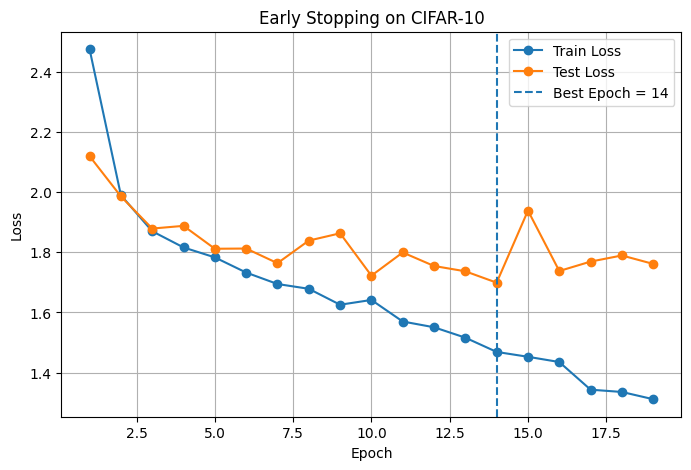

In [60]:
es_epochs = range(1, len(es_train_loss) + 1)

plt.figure(figsize=(8, 5))

plt.plot(
    es_epochs,
    es_train_loss,
    marker="o",
    label="Train Loss"
)

plt.plot(
    es_epochs,
    es_test_loss,
    marker="o",
    label="Test Loss"
)

best_epoch = np.argmin(es_test_loss) + 1

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch = {best_epoch}"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Early Stopping on CIFAR-10")
plt.legend()
plt.grid(True)

plt.show()

In [61]:
transfer_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [62]:
transfer_trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=False,
    transform=transfer_transform
)

transfer_testset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=False,
    transform=transfer_transform
)

In [63]:
transfer_small_trainset = Subset(
    transfer_trainset,
    range(5000)
)

transfer_trainloader = DataLoader(
    transfer_small_trainset,
    batch_size=32,
    shuffle=True
)

transfer_testloader = DataLoader(
    transfer_testset,
    batch_size=32,
    shuffle=False
)

print("Transfer training samples:", len(transfer_small_trainset))
print("Transfer test samples:", len(transfer_testset))

Transfer training samples: 5000
Transfer test samples: 10000


In [64]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT

transfer_model = resnet18(weights=weights)

print(transfer_model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/liuzhongbosmac/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████████████████████████████████| 44.7M/44.7M [00:01<00:00, 33.1MB/s]


Linear(in_features=512, out_features=1000, bias=True)


In [65]:
transfer_model.fc = nn.Linear(
    transfer_model.fc.in_features,
    10
)

print(transfer_model.fc)

Linear(in_features=512, out_features=10, bias=True)


In [66]:
for parameter in transfer_model.parameters():
    parameter.requires_grad = False

for parameter in transfer_model.fc.parameters():
    parameter.requires_grad = True

In [67]:
transfer_optimizer = optim.Adam(
    transfer_model.fc.parameters(),
    lr=0.001
)

transfer_criterion = nn.CrossEntropyLoss()

In [68]:
trainable_params = sum(
    p.numel()
    for p in transfer_model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in transfer_model.parameters()
)

print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)

Trainable parameters: 5130
Total parameters: 11181642


In [69]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

Using device: mps


In [70]:
transfer_model = transfer_model.to(device)

In [71]:
def train_transfer_model(
    model,
    optimizer,
    trainloader,
    testloader,
    criterion,
    device,
    num_epochs=5
):
    train_loss_history = []
    test_loss_history = []
    train_acc_history = []
    test_acc_history = []

    for epoch in range(num_epochs):

        # Training
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in trainloader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(trainloader)
        train_accuracy = 100 * correct / total

        # Evaluation
        model.eval()

        test_running_loss = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():
            for images, labels in testloader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                test_running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()

        test_loss = test_running_loss / len(testloader)
        test_accuracy = 100 * test_correct / test_total

        train_loss_history.append(train_loss)
        test_loss_history.append(test_loss)
        train_acc_history.append(train_accuracy)
        test_acc_history.append(test_accuracy)

        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Test Acc: {test_accuracy:.2f}%"
        )

    return (
        train_loss_history,
        test_loss_history,
        train_acc_history,
        test_acc_history
    )

In [72]:
(
    transfer_train_loss,
    transfer_test_loss,
    transfer_train_acc,
    transfer_test_acc
) = train_transfer_model(
    transfer_model,
    transfer_optimizer,
    transfer_trainloader,
    transfer_testloader,
    transfer_criterion,
    device,
    num_epochs=5
)

Epoch 1/5 | Train Loss: 1.4136 | Test Loss: 0.9651 | Train Acc: 56.20% | Test Acc: 70.43%
Epoch 2/5 | Train Loss: 0.8677 | Test Loss: 0.8258 | Train Acc: 73.82% | Test Acc: 72.53%
Epoch 3/5 | Train Loss: 0.7470 | Test Loss: 0.7405 | Train Acc: 75.92% | Test Acc: 75.26%
Epoch 4/5 | Train Loss: 0.6785 | Test Loss: 0.7180 | Train Acc: 78.06% | Test Acc: 75.90%
Epoch 5/5 | Train Loss: 0.6398 | Test Loss: 0.6920 | Train Acc: 78.58% | Test Acc: 76.43%
